# 06 — Truy nguyên nguyên nhân Accuracy thấp (rà soát độc lập)

Notebook này **làm lại từ đầu** mọi bước của notebook 01–05, không giả định bất kỳ kết luận nào
của các báo cáo trước. Với mỗi bước: nêu **vai trò**, nêu **kết quả mong đợi**, **kiểm chứng** bằng
số đo, và nếu lệch thì truy ra lý do.

**Kỷ luật đã tự áp đặt**

- Không sửa, không ghi đè bất kỳ file nào trong `data/`, `models/`, `notebooks/01..05`.
  Notebook này chỉ ghi vào `reports/audit06/`.
- `test-final` chỉ được chạm ở bước báo cáo cuối. Mọi lựa chọn ngưỡng/feature/model
  đều quyết định trên `validation` hoặc `test-dev`.
- Mỗi khẳng định phải kèm con số tạo ra nó. Không trích lại số của báo cáo cũ mà
  không tự đo lại.

**Câu hỏi cần trả lời:** Accuracy ~0,82 (ngưỡng 0,5) — thấp so với các bài báo công bố 97–98%
trên cùng bộ dữ liệu. Nguyên nhân nằm ở dữ liệu, ở cách làm sạch, hay ở cách cài đặt mô hình?

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

if os.environ.get('IDS_BASE'):                      # cho phep chay tu thu muc khac
    BASE = Path(os.environ['IDS_BASE'])
else:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        BASE = Path('/content/drive/MyDrive/5G_IDS_Project')
    except ImportError:
        BASE = Path(os.path.abspath('..'))          # notebook nam trong <project>/notebooks

RAW     = BASE / 'data' / 'raw' / 'CSV Files' / 'Training and Testing Sets'
CLEANED = BASE / 'data' / 'cleaned'
OUTDIR  = Path(os.environ.get('IDS_OUT') or (BASE / 'reports' / 'audit06'))
OUTDIR.mkdir(parents=True, exist_ok=True)

QUICK   = os.environ.get('QUICK') == '1'
RS      = 42
N_TREES = 40 if QUICK else 300

# Tham so Random Forest cua "lan 2" (duoc chon bang RandomizedSearchCV o notebook 03).
# Giu NGUYEN xuyen suot notebook nay de moi so sanh chi khac dung mot yeu to.
RF_PARAMS = dict(n_estimators=N_TREES, max_depth=20, max_features=0.5, max_samples=0.7,
                 min_samples_leaf=1, class_weight=None, random_state=RS, n_jobs=-1)

CATS    = ['proto', 'service', 'state']
TARGETS = ['label', 'attack_cat']
CONTAM  = ['ct_state_ttl', 'sttl', 'dttl', 'ct_dst_ltm', 'ct_srv_dst',
           'ct_dst_src_ltm', 'ct_srv_ltm', 'ct_srv_src', 'ct_dst_sport_ltm']
USELESS = ['is_sm_ips_ports', 'ct_ftp_cmd', 'is_ftp_login']

RESULTS = {}            # moi so do deu duoc gom vao day roi ghi ra JSON o cuoi
def log(key, value):
    RESULTS[key] = value
    return value

print('BASE    :', BASE)
print('Che do  :', 'QUICK (chi de kiem tra code)' if QUICK else 'FULL')
print('RF      :', RF_PARAMS)

BASE    : G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project
Che do  : FULL
RF      : {'n_estimators': 300, 'max_depth': 20, 'max_features': 0.5, 'max_samples': 0.7, 'min_samples_leaf': 1, 'class_weight': None, 'random_state': 42, 'n_jobs': -1}


---
# PHẦN 1 — Rà soát bước LÀM SẠCH (notebook 01)

| Bước | Vai trò | Kết quả mong đợi |
|---|---|---|
| 1.1 Đọc dữ liệu thô | Lấy đúng bộ chia chính thức của UNSW-NB15 | train 175.341 × 45, test 82.332 × 45, 0 NaN |
| 1.2 `df_shrink` | Giảm bộ nhớ, **không** được đổi nội dung | Kết quả bỏ trùng không đổi |
| 1.3 Bỏ cột | Loại feature ô nhiễm (D'hooge 2022) + metadata | Còn 31 feature + 2 cột nhãn |
| 1.4 Bỏ dòng trùng | Chống rò rỉ test→train và chống thuộc lòng | Không còn dòng trùng |
| 1.5 Bỏ dòng mâu thuẫn | Cùng feature mà khác nhãn thì không học được | Không còn nhóm mâu thuẫn |
| 1.6 Đối chiếu | Hàm ở đây phải là bản sao trung thực của notebook 01 | Trùng khít `data/cleaned` từng giá trị |

In [2]:
# ---- 1.1 Doc du lieu tho ----------------------------------------------------
raw = {}
for split in ['training', 'testing']:
    raw[split] = pd.read_csv(RAW / f'UNSW_NB15_{split}-set.csv', skipinitialspace=True, low_memory=False)

tbl = pd.DataFrame({
    s: {'so dong': len(d), 'so cot': d.shape[1], 'NaN': int(d.isna().sum().sum()),
        'ty le Attack': round(d['label'].mean(), 4)} for s, d in raw.items()}).T
display(tbl)

assert raw['training'].shape == (175341, 45), raw['training'].shape
assert raw['testing'].shape  == (82332, 45),  raw['testing'].shape
assert sum(d.isna().sum().sum() for d in raw.values()) == 0
log('1.1_raw', tbl.to_dict())
print('KIEM CHUNG 1.1: DAT — dung kich thuoc, khong co gia tri thieu.')
print('\nLUU Y: file ten "training-set" LON HON file "testing-set" (175k vs 82k).')
print('Day la dac diem that cua bo UNSW-NB15, khong phai loi dat ten cua nhom.')

,so dong,so cot,NaN,ty le Attack
training,175341.0,45.0,0.0,0.6806
testing,82332.0,45.0,0.0,0.5506


KIEM CHUNG 1.1: DAT — dung kich thuoc, khong co gia tri thieu.

LUU Y: file ten "training-set" LON HON file "testing-set" (175k vs 82k).
Day la dac diem that cua bo UNSW-NB15, khong phai loi dat ten cua nhom.


In [3]:
# ---- 1.2 df_shrink co lam mat thong tin khong? ------------------------------
from fastai.tabular.all import df_shrink

chk = {}
for split, d0 in raw.items():
    d = d0.drop(columns=['id'])
    s = df_shrink(d.copy(), skip=[], obj2cat=True, int2uint=False)
    num = d.select_dtypes(include=[np.number]).columns
    err = {c: float(np.nanmax(np.abs(d[c].astype('float64') - s[c].astype('float64')))) for c in num}
    worst = max(err, key=err.get)
    rel = err[worst] / max(abs(d[worst]).max(), 1)
    chk[split] = {'cot sai so lon nhat': worst,
                  'sai so tuyet doi': err[worst],
                  'sai so tuong doi': rel,
                  'bo nho truoc (MB)': round(d.memory_usage(deep=True).sum() / 1e6, 1),
                  'bo nho sau (MB)':  round(s.memory_usage(deep=True).sum() / 1e6, 1),
                  'so dong trung TRUOC shrink': int(d.drop(columns=[c for c in CONTAM+USELESS if c in d.columns]).duplicated().sum()),
                  'so dong trung SAU shrink':  int(s.drop(columns=[c for c in CONTAM+USELESS if c in s.columns]).duplicated().sum())}
display(pd.DataFrame(chk).T)
log('1.2_shrink', chk)

for s, v in chk.items():
    assert v['so dong trung TRUOC shrink'] == v['so dong trung SAU shrink'], s
print('KIEM CHUNG 1.2: DAT (co dieu kien).')
print('  df_shrink ha float64 -> float32 nen KHONG bao toan bit: sai so tuyet doi lon nhat'
      f" {max(v['sai so tuyet doi'] for v in chk.values()):.3g},"
      f" tuong doi {max(v['sai so tuong doi'] for v in chk.values()):.2e}.")
print('  Nhung so dong trung dem duoc GIONG HET truoc va sau -> buoc 1.4 khong bi anh huong.')

,cot sai so lon nhat,sai so tuyet doi,sai so tuong doi,bo nho truoc (MB),bo nho sau (MB),so dong trung TRUOC shrink,so dong trung SAU shrink
training,sjit,0.062,0.0,64.4,19.6,75775,75775
testing,sjit,0.06,0.0,30.2,9.2,31523,31523


KIEM CHUNG 1.2: DAT (co dieu kien).
  df_shrink ha float64 -> float32 nen KHONG bao toan bit: sai so tuyet doi lon nhat 0.062, tuong doi 4.25e-08.
  Nhung so dong trung dem duoc GIONG HET truoc va sau -> buoc 1.4 khong bi anh huong.


In [4]:
# ---- 1.3 / 1.4 / 1.5  Lam sach, tai lap chinh xac notebook 01 ---------------
def clean(df_raw, drop_cols=True, dedup=True):
    df = df_raw.drop(columns=['id'])
    df = df_shrink(df, skip=[], obj2cat=True, int2uint=False)
    st = {'rows_raw': len(df), 'attack_rate_raw': float(df['label'].mean())}
    if drop_cols:
        tod = [c for c in CONTAM + USELESS if c in df.columns]
        st['khong_tim_thay'] = [c for c in CONTAM + USELESS if c not in df.columns]
        df = df.drop(columns=tod)
        st['so_cot_da_bo'] = len(tod)
    feats = [c for c in df.columns if c not in TARGETS]
    if dedup:
        n = len(df)
        # tach rieng tac dong len tung LOP - cho ma bao cao cu chua soi ky
        by_class_before = df.groupby('label').size().to_dict()
        df = df.drop_duplicates()
        by_class_after = df.groupby('label').size().to_dict()
        st['dup_removed'] = n - len(df)
        st['dup_removed_normal'] = by_class_before[0] - by_class_after[0]
        st['dup_removed_attack'] = by_class_before[1] - by_class_after[1]
        st['attack_rate_sau_bo_trung'] = float(df['label'].mean())
        nun = df.groupby(feats, observed=True, dropna=False)['label'].transform('nunique')
        st['contra_removed'] = int((nun > 1).sum())
        df = df[nun == 1].reset_index(drop=True)
    st['rows_final'], st['cols_final'] = df.shape
    st['attack_rate_final'] = float(df['label'].mean())
    return df, st

cleaned, stats = {}, {}
for split, d in raw.items():
    cleaned[split], stats[split] = clean(d)
display(pd.DataFrame(stats).T)
log('1.3_cleaning', stats)

,rows_raw,attack_rate_raw,khong_tim_thay,so_cot_da_bo,dup_removed,dup_removed_normal,dup_removed_attack,attack_rate_sau_bo_trung,contra_removed,rows_final,cols_final,attack_rate_final
training,175341,0.680622,[ct_srv_ltm],11,75775,5862,69913,0.496435,632,98934,33,0.496381
testing,82332,0.5506,[ct_srv_ltm],11,31523,4846,26677,0.367159,242,50567,33,0.366504


{'training': {'rows_raw': 175341,
  'attack_rate_raw': 0.6806223302022916,
  'khong_tim_thay': ['ct_srv_ltm'],
  'so_cot_da_bo': 11,
  'dup_removed': 75775,
  'dup_removed_normal': 5862,
  'dup_removed_attack': 69913,
  'attack_rate_sau_bo_trung': 0.496434525842155,
  'contra_removed': 632,
  'rows_final': 98934,
  'cols_final': 33,
  'attack_rate_final': 0.4963814260011725},
 'testing': {'rows_raw': 82332,
  'attack_rate_raw': 0.5506000097167566,
  'khong_tim_thay': ['ct_srv_ltm'],
  'so_cot_da_bo': 11,
  'dup_removed': 31523,
  'dup_removed_normal': 4846,
  'dup_removed_attack': 26677,
  'attack_rate_sau_bo_trung': 0.36715936153043754,
  'contra_removed': 242,
  'rows_final': 50567,
  'cols_final': 33,
  'attack_rate_final': 0.3665038463820278}}

In [5]:
# ---- PHAT HIEN: buoc bo trung tac dong RAT KHAC NHAU len hai lop ------------
rows = []
for split, st in stats.items():
    n0 = raw[split].groupby('label').size()
    rows.append({'tap': split,
                 'Normal tho': int(n0[0]), 'Normal bi xoa': st['dup_removed_normal'],
                 '% Normal bi xoa': st['dup_removed_normal'] / n0[0],
                 'Attack tho': int(n0[1]), 'Attack bi xoa': st['dup_removed_attack'],
                 '% Attack bi xoa': st['dup_removed_attack'] / n0[1],
                 'attack_rate truoc': st['attack_rate_raw'],
                 'attack_rate sau':  st['attack_rate_sau_bo_trung']})
dup_tbl = pd.DataFrame(rows).set_index('tap')
display(dup_tbl.round(4))
log('1.4_dedup_by_class', dup_tbl.round(6).to_dict())

print('DOC BANG TREN:')
for s, r in dup_tbl.iterrows():
    print(f"  {s}: bo trung xoa {r['% Attack bi xoa']:.1%} dong Attack nhung chi {r['% Normal bi xoa']:.1%} dong Normal"
          f"  ({r['% Attack bi xoa']/r['% Normal bi xoa']:.1f} lan).")
print('\n=> Co che: luu luong tan cong (nhat la Generic) lap lai gan nhu y het nhau, nen bi gop lai rat nhieu.')
print('   Day la LY DO attack_rate tut tu ~0,68 xuong ~0,50 o train va ~0,55 xuong ~0,37 o test.')
print('   KHOANG LECH giua hai tap thi gan nhu KHONG doi -> xem 1.5.')

,Normal tho,Normal bi xoa,% Normal bi xoa,Attack tho,Attack bi xoa,% Attack bi xoa,attack_rate truoc,attack_rate sau
tap,,,,,,,,
training,56000,5862,0.1047,119341,69913,0.5858,0.6806,0.4964
testing,37000,4846,0.1310,45332,26677,0.5885,0.5506,0.3672


DOC BANG TREN:
  training: bo trung xoa 58.6% dong Attack nhung chi 10.5% dong Normal  (5.6 lan).
  testing: bo trung xoa 58.8% dong Attack nhung chi 13.1% dong Normal  (4.5 lan).

=> Co che: luu luong tan cong (nhat la Generic) lap lai gan nhu y het nhau, nen bi gop lai rat nhieu.
   Day la LY DO attack_rate tut tu ~0,68 xuong ~0,50 o train va ~0,55 xuong ~0,37 o test.
   KHOANG LECH giua hai tap thi gan nhu KHONG doi -> xem 1.5.


In [6]:
# ---- 1.5 Buoc lam sach co TAO RA lech ty le lop giua train/test khong? ------
gap = pd.DataFrame({
    'train': [stats['training']['attack_rate_raw'], stats['training']['attack_rate_final']],
    'test':  [stats['testing']['attack_rate_raw'],  stats['testing']['attack_rate_final']],
}, index=['truoc lam sach', 'sau lam sach'])
gap['lech (train - test)'] = gap['train'] - gap['test']
display(gap.round(4))
log('1.5_prevalence_gap', gap.round(6).to_dict())

d_tr = gap.loc['truoc lam sach', 'train'] - gap.loc['sau lam sach', 'train']
d_te = gap.loc['truoc lam sach', 'test']  - gap.loc['sau lam sach', 'test']
print(f'Muc giam cua train: {d_tr:.4f} | cua test: {d_te:.4f} | chenh nhau: {abs(d_tr-d_te):.4f}')
print(f"Lech truoc: {gap.loc['truoc lam sach','lech (train - test)']:.4f} | "
      f"sau: {gap.loc['sau lam sach','lech (train - test)']:.4f}")
print('\nKET LUAN 1.5: buoc lam sach KHONG tao ra lech ty le lop. Lech ~0,13 diem DA CO SAN')
print('trong du lieu tho. Lam sach keo ca hai tap xuong gan nhu bang nhau va giu nguyen khoang lech.')

,train,test,lech (train - test)
truoc lam sach,0.6806,0.5506,0.1300
sau lam sach,0.4964,0.3665,0.1299


Muc giam cua train: 0.1842 | cua test: 0.1841 | chenh nhau: 0.0001
Lech truoc: 0.1300 | sau: 0.1299

KET LUAN 1.5: buoc lam sach KHONG tao ra lech ty le lop. Lech ~0,13 diem DA CO SAN
trong du lieu tho. Lam sach keo ca hai tap xuong gan nhu bang nhau va giu nguyen khoang lech.


In [7]:
# ---- 1.6 Doi chieu voi data/cleaned da luu ---------------------------------
ok = {}
for split in ['training', 'testing']:
    saved = pd.read_parquet(CLEANED / f'UNSW_NB15_{split}-set.parquet')
    mine  = cleaned[split]
    same_shape = saved.shape == mine.shape
    same_vals  = same_shape and bool((mine[saved.columns].astype(str).values == saved.astype(str).values).all())
    ok[split] = {'shape da luu': str(saved.shape), 'shape tai lap': str(mine.shape),
                 'trung khit tung gia tri': same_vals}
display(pd.DataFrame(ok).T)
log('1.6_reproduction', ok)
assert all(v['trung khit tung gia tri'] for v in ok.values()), 'Khong tai lap duoc -> moi so sau deu vo nghia'
print('KIEM CHUNG 1.6: DAT — ham clean() o day la ban sao trung thuc cua notebook 01.')
print('=> Buoc lam sach KHONG co loi cai dat.')

,shape da luu,shape tai lap,trung khit tung gia tri
training,"(98934, 33)","(98934, 33)",True
testing,"(50567, 33)","(50567, 33)",True


KIEM CHUNG 1.6: DAT — ham clean() o day la ban sao trung thuc cua notebook 01.
=> Buoc lam sach KHONG co loi cai dat.


### Kết luận Phần 1

- Bước làm sạch **tái lập trùng khít từng giá trị** với `data/cleaned`. Không có lỗi cài đặt.
- `df_shrink` làm mất một ít độ chính xác (float64 → float32) nhưng **không** đổi kết quả bỏ trùng.
- Phát hiện mới về **cơ chế**: bỏ trùng xoá ~59% dòng Attack nhưng chỉ ~10–13% dòng Normal.
  Đó là lý do tỷ lệ Attack tụt mạnh ở cả hai tập.
- **Lệch tỷ lệ lớp ~13 điểm giữa train và test có sẵn trong dữ liệu thô**, không phải do làm sạch tạo ra.
  (Đây là chỗ cần sửa trong báo cáo cũ và slide.)

---
# PHẦN 2 — Rà soát TIỀN XỬ LÝ và MÔ HÌNH (notebook 02–04)

| Bước | Vai trò | Kết quả mong đợi |
|---|---|---|
| 2.1 Chia tập | Có tập chọn tham số/ngưỡng tách khỏi tập báo cáo | 79.147 / 19.787 / 25.283 / 25.284, stratify đúng |
| 2.2 One-Hot | Mã hoá biến định danh, **không** tạo thứ tự giả, **không** rò rỉ | Encoder chỉ fit trên train-fit; giá trị lạ → vector 0 |
| 2.3 Random Forest | Mô hình phân loại | Tái lập đúng số của báo cáo cũ |
| 2.4 Chẩn đoán | Model đang **underfit** hay **overfit**? | Xác định được bằng số, không đoán |

In [8]:
# ---- 2.1 Chia tap (dung y het notebook 03/04) -------------------------------
from sklearn.model_selection import train_test_split

train_c, test_c = cleaned['training'], cleaned['testing']
i_tr, i_val  = train_test_split(train_c.index, test_size=0.2,  stratify=train_c['label'],      random_state=RS)
i_dev, i_fin = train_test_split(test_c.index,  test_size=0.5,  stratify=test_c['attack_cat'],  random_state=RS)
TR, VAL, DEV, FIN = train_c.loc[i_tr], train_c.loc[i_val], test_c.loc[i_dev], test_c.loc[i_fin]

sz = pd.DataFrame({'so dong': [len(TR), len(VAL), len(DEV), len(FIN)],
                   'ty le Attack': [TR.label.mean(), VAL.label.mean(), DEV.label.mean(), FIN.label.mean()]},
                  index=['train-fit', 'validation', 'test-dev', 'test-final'])
display(sz.round(4))
log('2.1_splits', sz.round(6).to_dict())
assert [len(TR), len(VAL), len(DEV), len(FIN)] == [79147, 19787, 25283, 25284]
print('KIEM CHUNG 2.1: DAT — kich thuoc trung voi bao cao cu.')
print(f"\nDIEM CAN GHI NHO: train-fit co {TR.label.mean():.1%} Attack, test-final chi co {FIN.label.mean():.1%}.")
print('Mo hinh se hoc xac suat theo ty le cua TRAIN, roi bi cham diem tren tap co ty le KHAC.')

,so dong,ty le Attack
train-fit,79147,0.4964
validation,19787,0.4964
test-dev,25283,0.3665
test-final,25284,0.3665


KIEM CHUNG 2.1: DAT — kich thuoc trung voi bao cao cu.

DIEM CAN GHI NHO: train-fit co 49.6% Attack, test-final chi co 36.7%.
Mo hinh se hoc xac suat theo ty le cua TRAIN, roi bi cham diem tren tap co ty le KHAC.


In [9]:
# ---- 2.2 Kiem tra One-Hot: co ro ri khong, co xu ly duoc gia tri la khong? ---
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def X_of(df, cols=None):
    cols = cols or [c for c in df.columns if c not in TARGETS]
    return df[cols].astype({c: str for c in CATS if c in cols})

def make_pre(cols, dense=False):
    # dense=True cho HistGradientBoosting (khong nhan ma tran thua);
    # Random Forest dung ma tran thua cho nhe bo nho. Ket qua ma hoa y het nhau.
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), [c for c in CATS if c in cols])],
                             remainder='passthrough', verbose_feature_names_out=False,
                             sparse_threshold=0.0 if dense else 0.3)

FEATS31 = [c for c in train_c.columns if c not in TARGETS]
pre = make_pre(FEATS31).fit(X_of(TR))
names = pre.get_feature_names_out()

unseen = {c: sorted(set(test_c[c].astype(str)) - set(TR[c].astype(str))) for c in CATS}
enc_dev = pre.transform(X_of(DEV))
cat_block = enc_dev[:, :sum(len(cat) for cat in pre.named_transformers_['cat'].categories_)]
all_zero = int(np.asarray((cat_block.sum(axis=1) == 0)).sum()) if hasattr(cat_block, 'sum') else 0

info = {'so cot sau one-hot': int(len(names)),
        'gia tri chi co o test': unseen,
        'so dong test-dev bi ma hoa toan 0 o khoi categorical': all_zero,
        'encoder fit tren': 'CHI train-fit (khong co test)'}
print(json.dumps(info, ensure_ascii=False, indent=2))
log('2.2_onehot', info)
assert len(names) == 183, len(names)
print('\nKIEM CHUNG 2.2: DAT.')
print('  - 31 feature -> 183 cot. Dung nhu bao cao cu.')
print(f"  - Gia tri la ({unseen['state']}) duoc ma hoa thanh vector 0, khong gay loi, khong gay ro ri.")
print('  - One-Hot (khong phai LabelEncoder) nen khong tao thu tu gia giua cac giao thuc.')
print('  => Buoc tien xu ly KHONG co loi cai dat.')

{
  "so cot sau one-hot": 183,
  "gia tri chi co o test": {
    "proto": [],
    "service": [],
    "state": [
      "ACC",
      "CLO"
    ]
  },
  "so dong test-dev bi ma hoa toan 0 o khoi categorical": 0,
  "encoder fit tren": "CHI train-fit (khong co test)"
}

KIEM CHUNG 2.2: DAT.
  - 31 feature -> 183 cot. Dung nhu bao cao cu.
  - Gia tri la (['ACC', 'CLO']) duoc ma hoa thanh vector 0, khong gay loi, khong gay ro ri.
  - One-Hot (khong phai LabelEncoder) nen khong tao thu tu gia giua cac giao thuc.
  => Buoc tien xu ly KHONG co loi cai dat.


In [10]:
# ---- 2.3 Tai lap baseline ---------------------------------------------------
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             balanced_accuracy_score)

def rf_pipe(cols, **kw):
    return Pipeline([('pre', make_pre(cols)),
                     ('clf', RandomForestClassifier(**(RF_PARAMS | kw)))])

def hgb_pipe(cols):
    return Pipeline([('pre', make_pre(cols, dense=True)),
                     ('clf', HistGradientBoostingClassifier(
                         max_iter=100 if QUICK else 500, learning_rate=0.1, max_leaf_nodes=31,
                         min_samples_leaf=20, early_stopping=True, validation_fraction=0.1,
                         random_state=RS))])

def ev(y, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(threshold=round(float(thr), 4), accuracy=accuracy_score(y, pred),
                balanced_acc=balanced_accuracy_score(y, pred),
                precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred),
                f1=f1_score(y, pred), fpr=fp/(fp+tn), roc_auc=roc_auc_score(y, proba),
                pr_auc=average_precision_score(y, proba),
                TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))

t0 = time.time()
rf_A = rf_pipe(FEATS31).fit(X_of(TR), TR.label.values)
p_val = rf_A.predict_proba(X_of(VAL))[:, 1]
p_dev = rf_A.predict_proba(X_of(DEV))[:, 1]
p_fin = rf_A.predict_proba(X_of(FIN))[:, 1]
print(f'fit {time.time()-t0:.0f}s')

base = pd.DataFrame({'validation': ev(VAL.label.values, p_val),
                     'test-dev':   ev(DEV.label.values, p_dev),
                     'test-final': ev(FIN.label.values, p_fin)}).T
display(base.round(4))
log('2.3_baseline', base.round(6).to_dict())
BASELINE_ACC = float(base.loc['test-final', 'accuracy'])
print(f'\nAccuracy baseline tren test-final = {BASELINE_ACC:.4f}')
print('Bao cao cu ghi 0,8186 cho cung cau hinh. Sai lech o day la do so cay/seed, khong dang ke.')

fit 50s


,threshold,accuracy,balanced_acc,precision,recall,f1,fpr,roc_auc,pr_auc,TN,FP,FN,TP
validation,0.5,0.9322,0.9324,0.9104,0.9577,0.9335,0.0929,0.9860,0.9849,9039.0,926.0,415.0,9407.0
test-dev,0.5,0.8154,0.8438,0.6767,0.9504,0.7905,0.2627,0.9600,0.9429,11810.0,4207.0,460.0,8806.0
test-final,0.5,0.8186,0.8461,0.6813,0.9491,0.7932,0.2569,0.9594,0.9414,11903.0,4114.0,472.0,8795.0



Accuracy baseline tren test-final = 0.8186
Bao cao cu ghi 0,8186 cho cung cau hinh. Sai lech o day la do so cay/seed, khong dang ke.


In [11]:
# ---- 2.4 Underfit hay overfit? ---------------------------------------------
from sklearn.model_selection import cross_val_score, StratifiedKFold

p_tr_in = rf_A.predict_proba(X_of(TR))[:, 1]
cv = StratifiedKFold(n_splits=2 if QUICK else 5, shuffle=True, random_state=RS)
cv_pr = cross_val_score(rf_pipe(FEATS31), X_of(TR), TR.label.values,
                        scoring='average_precision', cv=cv, n_jobs=1)

lad = pd.DataFrame({
    'PR-AUC': [average_precision_score(TR.label.values, p_tr_in), cv_pr.mean(),
               average_precision_score(VAL.label.values, p_val),
               average_precision_score(DEV.label.values, p_dev),
               average_precision_score(FIN.label.values, p_fin)],
    'Accuracy @0,5': [accuracy_score(TR.label.values, p_tr_in >= .5), np.nan,
                      accuracy_score(VAL.label.values, p_val >= .5),
                      accuracy_score(DEV.label.values, p_dev >= .5),
                      accuracy_score(FIN.label.values, p_fin >= .5)],
}, index=['train-fit (hoc thuoc)', f'CV {cv.n_splits}-fold trong train-fit',
          'validation (cung phan bo train)', 'test-dev (phan bo test)', 'test-final (phan bo test)'])
display(lad.round(4))
log('2.4_fit_ladder', {'bang': lad.round(6).to_dict(), 'cv_std': float(cv_pr.std())})

print(f'CV PR-AUC = {cv_pr.mean():.4f} (do lech chuan giua cac fold {cv_pr.std():.4f})')
print(f'Khoang tut tu CV sang test-final = {cv_pr.mean() - average_precision_score(FIN.label.values, p_fin):.4f}'
      f' = {(cv_pr.mean()-average_precision_score(FIN.label.values,p_fin))/max(cv_pr.std(),1e-9):.0f} lan do lech chuan CV')
print()
print('CHAN DOAN:')
print('  - Trong CUNG phan bo train (CV va validation), model dat PR-AUC ~0,98 va Accuracy ~0,95.')
print('    => KHONG underfit. Suc bieu dien cua Random Forest la du.')
print('  - Chuyen sang phan bo test, PR-AUC tut ~0,04 va Accuracy tut ~0,13.')
print('    => Van de KHONG nam o do phuc tap cua model, ma o viec TAP TEST KHAC PHAN BO voi TAP TRAIN.')
print('  - Day khong phai "overfit" theo nghia hoc thuoc nhieu: train-fit va validation sat nhau.')
print('    Day la LECH PHAN BO (dataset shift) giua hai tap.')

,PR-AUC,"Accuracy @0,5"
train-fit (hoc thuoc),0.9985,0.9775
CV 5-fold trong train-fit,0.9830,NaN
validation (cung phan bo train),0.9849,0.9322
test-dev (phan bo test),0.9429,0.8154
test-final (phan bo test),0.9414,0.8186


CV PR-AUC = 0.9830 (do lech chuan giua cac fold 0.0015)
Khoang tut tu CV sang test-final = 0.0416 = 28 lan do lech chuan CV

CHAN DOAN:
  - Trong CUNG phan bo train (CV va validation), model dat PR-AUC ~0,98 va Accuracy ~0,95.
    => KHONG underfit. Suc bieu dien cua Random Forest la du.
  - Chuyen sang phan bo test, PR-AUC tut ~0,04 va Accuracy tut ~0,13.
    => Van de KHONG nam o do phuc tap cua model, ma o viec TAP TEST KHAC PHAN BO voi TAP TRAIN.
  - Day khong phai "overfit" theo nghia hoc thuoc nhieu: train-fit va validation sat nhau.
    Day la LECH PHAN BO (dataset shift) giua hai tap.


### Kết luận Phần 2

Không tìm thấy lỗi cài đặt nào trong tiền xử lý hay mô hình:

- One-Hot đúng loại mã hoá, chỉ fit trên train, xử lý được giá trị lạ, không rò rỉ.
- Cách chia tập đúng, có stratify, `test-final` được giữ sạch.
- Random Forest **không underfit** (CV PR-AUC ~0,98 trong phân bố train) và **không học thuộc quá mức**
  (train-fit và validation sát nhau).

Toàn bộ mức tụt xảy ra **đúng lúc chuyển từ phân bố train sang phân bố test**.
Phần 3 đo xem mức tụt đó đến từ đâu.

---
# PHẦN 3 — Accuracy đi đâu? Thiết kế thí nghiệm 2×2×2

Ba yếu tố bị nghi ngờ, tách bạch bằng một thiết kế giai thừa đầy đủ.
**Cùng thuật toán, cùng tham số, cùng seed** ở cả 8 ô — chỉ ba yếu tố dưới đây thay đổi:

| Yếu tố | Mức A | Mức B |
|---|---|---|
| **Cách chia train/test** | `official` — bộ chia chính thức của UNSW-NB15 | `random` — chia ngẫu nhiên có stratify, **cùng tỷ lệ kích thước** |
| **Bộ feature** | `31` — bỏ 8 feature ô nhiễm + 3 vô dụng | `42` — giữ nguyên tất cả |
| **Khử trùng lặp** | `có` | `không` |

Để so sánh công bằng, cả hai cách chia dùng **cùng một tập dòng**: gộp train+test rồi khử trùng lặp
**toàn cục** (nên không có dòng test nào là bản sao của dòng train), sau đó mới gán nhãn train/test
theo nguồn gốc (official) hoặc ngẫu nhiên (random).

In [12]:
# ---- 3.1 Dung be du lieu gop va chay thang do 2x2x2 -------------------------
def pool(drop_cols, dedup):
    parts = []
    for split, d in raw.items():
        x = d.copy(); x['__origin'] = split
        parts.append(x)
    df = pd.concat(parts, ignore_index=True).drop(columns=['id'])
    if drop_cols:
        df = df.drop(columns=[c for c in CONTAM + USELESS if c in df.columns])
    feats = [c for c in df.columns if c not in TARGETS + ['__origin']]
    if dedup:
        df = df.drop_duplicates(subset=feats + ['label'])
        nun = df.groupby(feats, observed=True, dropna=False)['label'].transform('nunique')
        df = df[nun == 1]
    return df.reset_index(drop=True), feats

# % dong test trung khit (feature + label) voi mot dong train.
# Dung hash theo dong cua pandas (C) thay vi ghep chuoi -> nhanh hon hang chuc lan.
def leak_pct(df, feats, m_train):
    h = pd.util.hash_pandas_object(df[feats + ['label']], index=False).values
    return float(np.isin(h[~m_train], h[m_train]).mean())

def run_cell(drop_cols, dedup, split_mode):
    df, feats = pool(drop_cols, dedup)
    X, y = X_of(df, feats), df['label'].values
    if split_mode == 'official':
        m = (df['__origin'] == 'training').values
    else:
        frac = float((df['__origin'] == 'testing').mean())
        idx_tr, _ = train_test_split(np.arange(len(df)), test_size=frac, stratify=y, random_state=RS)
        m = np.zeros(len(df), bool); m[idx_tr] = True
    t = time.time()
    mdl = rf_pipe(feats).fit(X[m], y[m])
    pr = mdl.predict_proba(X[~m])[:, 1]
    r = ev(y[~m], pr)
    pi_tr, pi_te = y[m].mean(), y[~m].mean()
    a, b = pi_te / pi_tr, (1 - pi_te) / (1 - pi_tr)
    adj = pr * a / (pr * a + (1 - pr) * b)
    r.update(feature=('31 (bo 11)' if drop_cols else '42 (giu het)'),
             bo_trung=('co' if dedup else 'khong'), cach_chia=split_mode,
             n_train=int(m.sum()), n_test=int((~m).sum()),
             pi_train=round(float(pi_tr), 4), pi_test=round(float(pi_te), 4),
             ro_ri=round(leak_pct(df, feats, m), 4),
             acc_sau_sua_prior=accuracy_score(y[~m], (adj >= .5).astype(int)),
             giay=round(time.time() - t))
    return r

ladder = []
for dedup in [True, False]:
    for drop_cols in [True, False]:
        for mode in ['official', 'random']:
            r = run_cell(drop_cols, dedup, mode)
            ladder.append(r)
            print(f"bo_trung={r['bo_trung']:5s} feature={r['feature']:12s} chia={r['cach_chia']:8s} "
                  f"| ro_ri={r['ro_ri']:.3f} acc={r['accuracy']:.4f} prec={r['precision']:.4f} "
                  f"rec={r['recall']:.4f} fpr={r['fpr']:.4f} PR-AUC={r['pr_auc']:.4f} ({r['giay']}s)")

LAD = pd.DataFrame(ladder)
LAD.to_csv(OUTDIR / 'thang_do_2x2x2.csv', index=False)
log('3.1_ladder', LAD.round(6).to_dict('records'))

bo_trung=co    feature=31 (bo 11)   chia=official | ro_ri=0.000 acc=0.8145 prec=0.6550 rec=0.9383 fpr=0.2476 PR-AUC=0.9259 (80s)


bo_trung=co    feature=31 (bo 11)   chia=random   | ro_ri=0.000 acc=0.9102 prec=0.9003 rec=0.8854 fpr=0.0717 PR-AUC=0.9693 (77s)


bo_trung=co    feature=42 (giu het) chia=official | ro_ri=0.000 acc=0.8259 prec=0.6813 rec=0.9715 fpr=0.2562 PR-AUC=0.9466 (98s)


bo_trung=co    feature=42 (giu het) chia=random   | ro_ri=0.000 acc=0.9211 prec=0.9158 rec=0.9053 fpr=0.0663 PR-AUC=0.9778 (89s)


bo_trung=khong feature=31 (bo 11)   chia=official | ro_ri=0.286 acc=0.8633 prec=0.8136 rec=0.9752 fpr=0.2737 PR-AUC=0.9840 (118s)


bo_trung=khong feature=31 (bo 11)   chia=random   | ro_ri=0.475 acc=0.9400 prec=0.9583 rec=0.9473 fpr=0.0730 PR-AUC=0.9941 (108s)


bo_trung=khong feature=42 (giu het) chia=official | ro_ri=0.100 acc=0.8711 prec=0.8168 rec=0.9873 fpr=0.2713 PR-AUC=0.9859 (153s)


bo_trung=khong feature=42 (giu het) chia=random   | ro_ri=0.443 acc=0.9505 prec=0.9655 rec=0.9568 fpr=0.0606 PR-AUC=0.9958 (138s)


[{'threshold': 0.5,
  'accuracy': 0.814462,
  'balanced_acc': 0.845363,
  'precision': 0.655032,
  'recall': 0.938325,
  'f1': 0.771494,
  'fpr': 0.2476,
  'roc_auc': 0.954679,
  'pr_auc': 0.925936,
  'TN': 23666,
  'FP': 7788,
  'FN': 972,
  'TP': 14788,
  'feature': '31 (bo 11)',
  'bo_trung': 'co',
  'cach_chia': 'official',
  'n_train': 93462,
  'n_test': 47214,
  'pi_train': 0.4671,
  'pi_test': 0.3338,
  'ro_ri': 0.0,
  'acc_sau_sua_prior': 0.866035,
  'giay': 80},
 {'threshold': 0.5,
  'accuracy': 0.910175,
  'balanced_acc': 0.906841,
  'precision': 0.900311,
  'recall': 0.885368,
  'f1': 0.892777,
  'fpr': 0.071685,
  'roc_auc': 0.977106,
  'pr_auc': 0.969328,
  'TN': 25317,
  'FP': 1955,
  'FN': 2286,
  'TP': 17656,
  'feature': '31 (bo 11)',
  'bo_trung': 'co',
  'cach_chia': 'random',
  'n_train': 93462,
  'n_test': 47214,
  'pi_train': 0.4224,
  'pi_test': 0.4224,
  'ro_ri': 0.0,
  'acc_sau_sua_prior': 0.910196,
  'giay': 77},
 {'threshold': 0.5,
  'accuracy': 0.825912,
  '

In [13]:
# ---- 3.2 Doc ket qua thang do ----------------------------------------------
for metric in ['accuracy', 'pr_auc', 'fpr']:
    print(f'\n### {metric} ###')
    print(LAD.pivot_table(index=['bo_trung', 'feature'], columns='cach_chia', values=metric).round(4).to_string())

d = LAD[LAD.bo_trung == 'co']
eff_split = (d[d.cach_chia == 'random'].set_index('feature').accuracy
             - d[d.cach_chia == 'official'].set_index('feature').accuracy)
eff_feat = (d[d.feature == '42 (giu het)'].set_index('cach_chia').accuracy
            - d[d.feature == '31 (bo 11)'].set_index('cach_chia').accuracy)
e = LAD[(LAD.feature == '42 (giu het)') & (LAD.cach_chia == 'random')]
eff_dedup = float(e[e.bo_trung == 'khong'].accuracy.iloc[0] - e[e.bo_trung == 'co'].accuracy.iloc[0])

print('\n================= DO LON CUA TUNG YEU TO (accuracy) =================')
print(f'  Doi cach chia official -> random : {eff_split.mean():+.4f}  ({eff_split.round(4).to_dict()})')
print(f'  Giu lai 11 feature da bo         : {eff_feat.mean():+.4f}  ({eff_feat.round(4).to_dict()})')
print(f'  Bo buoc khu trung lap            : {eff_dedup:+.4f}  (nhung ro ri test->train tang vot, xem cot ro_ri)')
log('3.2_effects', {'cach_chia': float(eff_split.mean()), 'feature': float(eff_feat.mean()),
                    'bo_khu_trung_lap': eff_dedup})


### accuracy ###
cach_chia              official  random
bo_trung feature                       
co       31 (bo 11)      0.8145  0.9102
         42 (giu het)    0.8259  0.9211
khong    31 (bo 11)      0.8633  0.9400
         42 (giu het)    0.8711  0.9505

### pr_auc ###
cach_chia              official  random
bo_trung feature                       
co       31 (bo 11)      0.9259  0.9693
         42 (giu het)    0.9466  0.9778
khong    31 (bo 11)      0.9840  0.9941
         42 (giu het)    0.9859  0.9958

### fpr ###
cach_chia              official  random
bo_trung feature                       
co       31 (bo 11)      0.2476  0.0717
         42 (giu het)    0.2562  0.0663
khong    31 (bo 11)      0.2737  0.0730
         42 (giu het)    0.2713  0.0606

================= DO LON CUA TUNG YEU TO (accuracy) =================
  Doi cach chia official -> random : +0.0955  ({'31 (bo 11)': 0.0957, '42 (giu het)': 0.0952})
  Giu lai 11 feature da bo         : +0.0112  ({'official': 0.0115,

{'cach_chia': 0.09545345246560866,
 'feature': 0.011190358460340222,
 'bo_khu_trung_lap': 0.029399648240122644}

In [14]:
# ---- 3.3 Phap y: lech o dau? ----------------------------------------------
from scipy.stats import ks_2samp

tr_raw, te_raw = raw['training'], raw['testing']
num_cols = [c for c in tr_raw.columns
            if c not in CATS + ['id', 'label', 'attack_cat'] and pd.api.types.is_numeric_dtype(tr_raw[c])]
rows = []
for c in num_cols:
    rows.append({'feature': c,
                 'KS tat ca': ks_2samp(tr_raw[c], te_raw[c]).statistic,
                 'KS rieng Normal': ks_2samp(tr_raw.loc[tr_raw.label == 0, c], te_raw.loc[te_raw.label == 0, c]).statistic,
                 'KS rieng Attack': ks_2samp(tr_raw.loc[tr_raw.label == 1, c], te_raw.loc[te_raw.label == 1, c]).statistic,
                 'trung vi train': float(tr_raw[c].median()), 'trung vi test': float(te_raw[c].median())})
KS = pd.DataFrame(rows).sort_values('KS rieng Normal', ascending=False)
display(KS.head(12).round(4))
log('3.3_ks', KS.round(6).to_dict('records'))

# co cau loai tan cong
share = pd.DataFrame({'train': tr_raw.attack_cat.value_counts(normalize=True),
                      'test': te_raw.attack_cat.value_counts(normalize=True)}).fillna(0)
share['chenh'] = share.test - share.train
display(share.sort_values('chenh', key=abs, ascending=False).round(4))
log('3.3_attack_cat_share', share.round(6).to_dict())

print(f"KS trung binh tren {len(num_cols)} feature so: tat ca {KS['KS tat ca'].mean():.4f} | "
      f"rieng Normal {KS['KS rieng Normal'].mean():.4f} | rieng Attack {KS['KS rieng Attack'].mean():.4f}")
print('=> Lech tap trung o lop NORMAL, va o nhom feature thoi gian bat tay TCP.')

,feature,KS tat ca,KS rieng Normal,KS rieng Attack,trung vi train,trung vi test
6,sttl,0.0267,0.2763,0.0066,254.0000,254.0000
28,ct_state_ttl,0.0301,0.2559,0.0102,1.0000,1.0000
22,ackdat,0.0967,0.2383,0.0345,0.0000,0.0001
9,dload,0.0434,0.2348,0.0228,1447.0227,2112.9514
7,dttl,0.0669,0.2055,0.0072,29.0000,29.0000
20,tcprtt,0.0699,0.2023,0.0376,0.0000,0.0006
24,dmean,0.0436,0.2018,0.0094,44.0000,44.0000
21,synack,0.0647,0.2014,0.0366,0.0000,0.0004
4,dbytes,0.0437,0.1775,0.0120,164.0000,178.0000
14,sjit,0.0577,0.1590,0.0328,0.0000,17.6239


,train,test,chenh
attack_cat,,,
Normal,0.3194,0.4494,0.1300
Exploits,0.1904,0.1352,-0.0552
Fuzzers,0.1037,0.0736,-0.0301
DoS,0.0699,0.0497,-0.0203
Reconnaissance,0.0598,0.0425,-0.0174
Analysis,0.0114,0.0082,-0.0032
Backdoor,0.0100,0.0071,-0.0029
Shellcode,0.0065,0.0046,-0.0019
Generic,0.2281,0.2292,0.0011


KS trung binh tren 39 feature so: tat ca 0.0530 | rieng Normal 0.1097 | rieng Attack 0.0385
=> Lech tap trung o lop NORMAL, va o nhom feature thoi gian bat tay TCP.


In [15]:
# ---- 3.4 Lech do DICH CHUYEN TY LE LOP (prior shift) chiem bao nhieu? -------
pi_tr, pi_fin = TR.label.mean(), FIN.label.mean()
a, b = pi_fin / pi_tr, (1 - pi_fin) / (1 - pi_tr)
p_fin_adj = p_fin * a / (p_fin * a + (1 - p_fin) * b)

cmp = pd.DataFrame({
    'baseline @0,5':               ev(FIN.label.values, p_fin, 0.5),
    'chi sua PRIOR, van @0,5':     ev(FIN.label.values, p_fin_adj, 0.5),
}).T
display(cmp.round(4))
log('3.4_prior_fix', cmp.round(6).to_dict())
print(f'pi(train-fit) = {pi_tr:.4f} | pi(test-final) = {pi_fin:.4f}')
print(f"Chi bang mot phep sua ty le lop: accuracy {cmp.loc['baseline @0,5','accuracy']:.4f} -> "
      f"{cmp.loc['chi sua PRIOR, van @0,5','accuracy']:.4f} "
      f"({cmp.loc['chi sua PRIOR, van @0,5','accuracy']-cmp.loc['baseline @0,5','accuracy']:+.4f}), "
      f"FPR {cmp.loc['baseline @0,5','fpr']:.4f} -> {cmp.loc['chi sua PRIOR, van @0,5','fpr']:.4f}")
print('\nLUU Y TRUNG THUC: o day ty le lop cua test duoc lay tu NHAN that, nen day la chan tren.')
print('Phan 4 lam lai bang cach UOC LUONG ty le do tu du lieu test KHONG NHAN (thuat toan EM).')

,threshold,accuracy,balanced_acc,precision,recall,f1,fpr,roc_auc,pr_auc,TN,FP,FN,TP
"baseline @0,5",0.5,0.8186,0.8461,0.6813,0.9491,0.7932,0.2569,0.9594,0.9414,11903.0,4114.0,472.0,8795.0
"chi sua PRIOR, van @0,5",0.5,0.8673,0.8726,0.7784,0.8921,0.8314,0.1470,0.9594,0.9414,13663.0,2354.0,1000.0,8267.0


pi(train-fit) = 0.4964 | pi(test-final) = 0.3665
Chi bang mot phep sua ty le lop: accuracy 0.8186 -> 0.8673 (+0.0487), FPR 0.2569 -> 0.1470

LUU Y TRUNG THUC: o day ty le lop cua test duoc lay tu NHAN that, nen day la chan tren.
Phan 4 lam lai bang cach UOC LUONG ty le do tu du lieu test KHONG NHAN (thuat toan EM).


### Kết luận Phần 3 — nguyên nhân

Thang đo 2×2×2 cho thấy ba yếu tố **không ngang nhau chút nào**:

1. **Cách chia train/test là yếu tố áp đảo.** Đổi từ bộ chia chính thức sang chia ngẫu nhiên
   (giữ nguyên dữ liệu, thuật toán, tham số) làm accuracy nhảy khoảng **+9,6 điểm**.
2. **Việc bỏ 8 feature ô nhiễm chỉ đáng khoảng +1,1 điểm** — nhỏ hơn yếu tố trên gần 9 lần.
3. **Bỏ bước khử trùng lặp làm số đẹp lên** nhưng chỉ vì tỷ lệ dòng test là bản sao của dòng train
   tăng vọt — đó là điểm số ảo, không phải năng lực.

Trong mức chênh do cách chia, một phần lớn là **dịch chuyển tỷ lệ lớp** (train 49,6% Attack
so với test 36,7%): chỉ cần chỉnh lại tỷ lệ này là đã lấy lại được khoảng 5 điểm accuracy.
Phần còn lại là lệch phân bố thật của feature, tập trung ở lớp Normal và ở nhóm feature
thời gian bắt tay TCP.

**Vậy: Accuracy thấp KHÔNG phải do cài đặt mô hình sai.** Nó là hệ quả của (a) một quyết định
đánh giá — dùng bộ chia chính thức vốn bị lệch phân bố, và (b) một lỗi vận hành có thật nhưng
dễ sửa — để ngưỡng ở 0,5 trong khi mô hình được hiệu chỉnh theo tỷ lệ lớp của tập train.

---
# PHẦN 4 — Khắc phục

Mọi cấu hình dưới đây đều: fit trên `train-fit`, chọn ngưỡng/siêu tham số trên `validation`
hoặc `test-dev`, và **chỉ báo cáo trên `test-final`**.

Các hướng được thử:

| # | Hướng | Có dùng nhãn của test không? |
|---|---|---|
| 1 | Chọn ngưỡng tối ưu Accuracy trên validation | Không |
| 2 | **Sửa dịch chuyển tỷ lệ lớp** — ước lượng tỷ lệ Attack của miền test bằng EM (Saerens et al. 2002) từ dữ liệu test **không nhãn** | Không |
| 3 | 2 + chọn ngưỡng trên test-dev | Có (test-dev, không phải test-final) |
| 4 | **Căn chỉnh phân bố** — thay mỗi feature số bằng phân vị của nó trong chính tập của nó | Không |
| 5 | Bỏ nhóm feature lệch nhất | Không |
| 6 | HistGradientBoosting thay Random Forest | Không |
| 7 | Giữ lại 11 feature đã bỏ | Không |

In [16]:
# ---- 4.1 Cac cong cu khac phuc ---------------------------------------------
from sklearn.preprocessing import QuantileTransformer

# Saerens-Latinne-Decaestecker (2002): uoc luong ty le lop cua mien DICH
# chi tu xac suat du doan - KHONG dung nhan cua tap dich.
def em_prior(proba, pi_src, iters=500, tol=1e-10):
    pi = float(pi_src)
    for _ in range(iters):
        r = (proba * pi / pi_src) / (proba * pi / pi_src + (1 - proba) * (1 - pi) / (1 - pi_src))
        new = float(r.mean())
        if abs(new - pi) < tol:
            break
        pi = new
    return pi

def shift_prior(proba, pi_src, pi_dst):
    a, b = pi_dst / pi_src, (1 - pi_dst) / (1 - pi_src)
    return proba * a / (proba * a + (1 - proba) * b)

def best_acc_thr(y, proba):
    cand = np.unique(np.round(np.r_[np.arange(0.02, 0.99, 0.005), proba], 4))
    return float(cand[int(np.argmax([accuracy_score(y, proba >= t) for t in cand]))])

# Can chinh phan bo: moi feature so -> phan vi trong CHINH tap cua no.
# Co chu y fit RIENG tren tung tap; chi dung FEATURE cua test, khong dung nhan.
def rank_align(frames, num_cols):
    out = []
    for d in frames:
        d = d.copy()
        qt = QuantileTransformer(output_distribution='uniform', n_quantiles=1000,
                                 subsample=200000, random_state=RS)
        d[num_cols] = qt.fit_transform(d[num_cols])
        out.append(d)
    return out

# Nhanh 42 feature: giu dung TAP DONG cua nhanh 31 feature roi dinh 11 cot kia vao,
# de hai nhanh chi khac nhau dung 11 cot.
def cleaned_with_contaminants(split):
    d = raw[split].drop(columns=['id'])
    d = df_shrink(d, skip=[], obj2cat=True, int2uint=False)
    extra = [c for c in CONTAM + USELESS if c in d.columns]
    core = d.drop(columns=extra)
    f31 = [c for c in core.columns if c not in TARGETS]
    keep = core[~core.duplicated()]
    nun = keep.groupby(f31, observed=True, dropna=False)['label'].transform('nunique')
    return d.loc[keep.index[nun == 1]].reset_index(drop=True)

tr42_all, te42_all = cleaned_with_contaminants('training'), cleaned_with_contaminants('testing')
j_tr, j_val = train_test_split(tr42_all.index, test_size=0.2, stratify=tr42_all['label'], random_state=RS)
j_dev, j_fin = train_test_split(te42_all.index, test_size=0.5, stratify=te42_all['attack_cat'], random_state=RS)
TR42, VAL42, DEV42, FIN42 = tr42_all.loc[j_tr], tr42_all.loc[j_val], te42_all.loc[j_dev], te42_all.loc[j_fin]
FEATS42 = [c for c in tr42_all.columns if c not in TARGETS]
assert len(TR42) == len(TR) and len(FIN42) == len(FIN)
print(f'Nhanh 42 feature: {len(FEATS42)} cot, cung {len(TR42)} dong train-fit -> doi chung hop le.')

SHIFTED = ['ackdat', 'synack', 'tcprtt', 'dinpkt', 'sinpkt', 'sjit', 'djit']
FEATS24 = [c for c in FEATS31 if c not in SHIFTED]
print('Nhom feature lech nhat bi bo thu o cau hinh 5:', SHIFTED)

Nhanh 42 feature: 42 cot, cung 79147 dong train-fit -> doi chung hop le.
Nhom feature lech nhat bi bo thu o cau hinh 5: ['ackdat', 'synack', 'tcprtt', 'dinpkt', 'sinpkt', 'sjit', 'djit']


In [17]:
# ---- 4.2 Chay toan bo cau hinh ---------------------------------------------
def run_fix(name, data, cols, pipe_fn, align=False, prior_fix=False, thr_rule='0.5'):
    tr, val, dev, fin = data
    Xtr, Xval, Xdev, Xfin = (X_of(d, cols) for d in (tr, val, dev, fin))
    if align:
        num = [c for c in cols if c not in CATS]
        Xtr, Xval, Xdev, Xfin = rank_align([Xtr, Xval, Xdev, Xfin], num)
    ytr, yval, ydev, yfin = (d.label.values for d in (tr, val, dev, fin))
    t = time.time()
    m = pipe_fn(cols).fit(Xtr, ytr)
    pv, pd_, pf = (m.predict_proba(X)[:, 1] for X in (Xval, Xdev, Xfin))
    extra = {}
    if prior_fix:
        pi_hat = em_prior(pd_, ytr.mean())          # chi dung FEATURE cua test-dev
        extra = {'pi_train': round(float(ytr.mean()), 4), 'pi_test_uoc_luong_EM': round(pi_hat, 4),
                 'pi_test_that': round(float(ydev.mean()), 4)}
        pd_, pf = shift_prior(pd_, ytr.mean(), pi_hat), shift_prior(pf, ytr.mean(), pi_hat)
    thr = {'0.5': 0.5}.get(thr_rule) or (best_acc_thr(yval, pv) if thr_rule == 'val' else best_acc_thr(ydev, pd_))
    r = ev(yfin, pf, thr)
    r.update(name=name, so_feature=len(cols), giay=round(time.time() - t), **extra)
    return r, pf

D31, D42 = (TR, VAL, DEV, FIN), (TR42, VAL42, DEV42, FIN42)
JOBS = [
    ('0. RF 31f @0,5  (BASELINE)',                      D31, FEATS31, rf_pipe,  False, False, '0.5'),
    ('1. RF 31f + nguong Acc chon tren validation',     D31, FEATS31, rf_pipe,  False, False, 'val'),
    ('2. RF 31f + SUA PRIOR (EM, khong dung nhan test)',D31, FEATS31, rf_pipe,  False, True,  '0.5'),
    ('3. RF 31f + SUA PRIOR + nguong tren test-dev',    D31, FEATS31, rf_pipe,  False, True,  'dev'),
    ('4. RF 31f + CAN CHINH PHAN BO (phan vi)',         D31, FEATS31, rf_pipe,  True,  False, '0.5'),
    ('5. RF 31f + can chinh + sua prior',               D31, FEATS31, rf_pipe,  True,  True,  'dev'),
    ('6. RF 24f (bo nhom feature lech nhat)',           D31, FEATS24, rf_pipe,  False, False, '0.5'),
    ('7. RF 24f + sua prior',                           D31, FEATS24, rf_pipe,  False, True,  'dev'),
    ('8. HGB 31f @0,5',                                 D31, FEATS31, hgb_pipe, False, False, '0.5'),
    ('9. HGB 31f + sua prior',                          D31, FEATS31, hgb_pipe, False, True,  'dev'),
    ('10. RF 42f (giu feature o nhiem) @0,5',           D42, FEATS42, rf_pipe,  False, False, '0.5'),
    ('11. RF 42f + sua prior',                          D42, FEATS42, rf_pipe,  False, True,  'dev'),
    ('12. HGB 42f + sua prior',                         D42, FEATS42, hgb_pipe, False, True,  'dev'),
]

fixes, P = [], {}
for name, data, cols, fn, al, pf_, tr_ in JOBS:
    r, p = run_fix(name, data, cols, fn, al, pf_, tr_)
    fixes.append(r); P[name] = p
    print(f"{name:52s} thr={r['threshold']:.3f} acc={r['accuracy']:.4f} bal={r['balanced_acc']:.4f} "
          f"prec={r['precision']:.4f} rec={r['recall']:.4f} f1={r['f1']:.4f} fpr={r['fpr']:.4f} "
          f"PR-AUC={r['pr_auc']:.4f} ({r['giay']}s)")

FIX = pd.DataFrame(fixes)
FIX.to_csv(OUTDIR / 'cac_huong_khac_phuc.csv', index=False)
log('4.2_fixes', FIX.round(6).to_dict('records'))
display(FIX[['name', 'threshold', 'accuracy', 'balanced_acc', 'precision', 'recall', 'f1', 'fpr', 'pr_auc']].round(4))

0. RF 31f @0,5  (BASELINE)                           thr=0.500 acc=0.8186 bal=0.8461 prec=0.6813 rec=0.9491 f1=0.7932 fpr=0.2569 PR-AUC=0.9414 (54s)


1. RF 31f + nguong Acc chon tren validation          thr=0.535 acc=0.8335 bal=0.8550 prec=0.7059 rec=0.9354 f1=0.8046 fpr=0.2254 PR-AUC=0.9414 (57s)


2. RF 31f + SUA PRIOR (EM, khong dung nhan test)     thr=0.500 acc=0.8310 bal=0.8535 prec=0.7015 rec=0.9378 f1=0.8026 fpr=0.2309 PR-AUC=0.9414 (100s)


3. RF 31f + SUA PRIOR + nguong tren test-dev         thr=0.794 acc=0.8925 bal=0.8725 prec=0.8974 rec=0.7978 f1=0.8447 fpr=0.0528 PR-AUC=0.9414 (119s)


4. RF 31f + CAN CHINH PHAN BO (phan vi)              thr=0.500 acc=0.7314 bal=0.7561 prec=0.5934 rec=0.8485 f1=0.6984 fpr=0.3363 PR-AUC=0.7736 (106s)


...

9. HGB 31f + sua prior                               thr=0.841 acc=0.8930 bal=0.8704 prec=0.9097 rec=0.7860 f1=0.8433 fpr=0.0451 PR-AUC=0.9423 (76s)


10. RF 42f (giu feature o nhiem) @0,5                thr=0.500 acc=0.8353 bal=0.8643 prec=0.6974 rec=0.9727 f1=0.8124 fpr=0.2442 PR-AUC=0.9530 (121s)


11. RF 42f + sua prior                               thr=0.817 acc=0.9048 bal=0.8920 prec=0.8901 rec=0.8444 f1=0.8667 fpr=0.0603 PR-AUC=0.9530 (129s)


12. HGB 42f + sua prior                              thr=0.859 acc=0.9050 bal=0.8908 prec=0.8963 rec=0.8376 f1=0.8660 fpr=0.0561 PR-AUC=0.9544 (71s)


,name,threshold,accuracy,balanced_acc,precision,recall,f1,fpr,pr_auc
0,"0. RF 31f @0,5 (BASELINE)",0.5000,0.8186,0.8461,0.6813,0.9491,0.7932,0.2569,0.9414
1,1. RF 31f + nguong Acc chon tren validation,0.5349,0.8335,0.8550,0.7059,0.9354,0.8046,0.2254,0.9414
2,"2. RF 31f + SUA PRIOR (EM, khong dung nhan test)",0.5000,0.8310,0.8535,0.7015,0.9378,0.8026,0.2309,0.9414
3,3. RF 31f + SUA PRIOR + nguong tren test-dev,0.7944,0.8925,0.8725,0.8974,0.7978,0.8447,0.0528,0.9414
4,4. RF 31f + CAN CHINH PHAN BO (phan vi),0.5000,0.7314,0.7561,0.5934,0.8485,0.6984,0.3363,0.7736
5,5. RF 31f + can chinh + sua prior,0.7752,0.7617,0.7342,0.6917,0.6312,0.6600,0.1628,0.7736
6,6. RF 24f (bo nhom feature lech nhat),0.5000,0.8200,0.8476,0.6827,0.9510,0.7948,0.2557,0.9393
7,7. RF 24f + sua prior,0.7800,0.8903,0.8722,0.8858,0.8045,0.8432,0.0600,0.9393
8,"8. HGB 31f @0,5",0.5000,0.8215,0.8485,0.6850,0.9498,0.7959,0.2527,0.9423
9,9. HGB 31f + sua prior,0.8410,0.8930,0.8704,0.9097,0.7860,0.8433,0.0451,0.9423


In [18]:
# ---- 4.3 EM uoc luong ty le lop cua test co chinh xac khong? ---------------
emrows = FIX[FIX.pi_test_uoc_luong_EM.notna()][['name', 'pi_train', 'pi_test_uoc_luong_EM', 'pi_test_that']]
display(emrows)
log('4.3_em', emrows.to_dict('records'))
print('Neu cot "uoc luong EM" bam sat cot "that", nghia la co the sua dich chuyen ty le lop')
print('MA KHONG CAN nhan cua tap test -> hoan toan dung duoc trong trien khai that.')

,name,pi_train,pi_test_uoc_luong_EM,pi_test_that
2,"2. RF 31f + SUA PRIOR (EM, khong dung nhan test)",0.4964,0.4684,0.3665
3,3. RF 31f + SUA PRIOR + nguong tren test-dev,0.4964,0.4684,0.3665
5,5. RF 31f + can chinh + sua prior,0.4964,0.4759,0.3665
7,7. RF 24f + sua prior,0.4964,0.4727,0.3665
9,9. HGB 31f + sua prior,0.4964,0.4709,0.3665
11,11. RF 42f + sua prior,0.4964,0.4778,0.3665
12,12. HGB 42f + sua prior,0.4964,0.4837,0.3665


Neu cot "uoc luong EM" bam sat cot "that", nghia la co the sua dich chuyen ty le lop
MA KHONG CAN nhan cua tap test -> hoan toan dung duoc trong trien khai that.


---
## 4B — Thuật toán nào tối ưu cho bài toán này?

Chẩn đoán ở Phần 3 nói trần hiệu năng nằm ở dữ liệu. Phần này **kiểm chứng trực tiếp** nhận định đó:
nếu đúng, thì các họ thuật toán khác hẳn nhau về cơ chế sẽ cho **cùng một mức PR-AUC** trên test-final.

Mọi thuật toán dùng chung: 31 feature, cùng cách chia, cùng seed, không dò siêu tham số diện rộng.

| Thuật toán | Cơ chế | Lý do đưa vào |
|---|---|---|
| Random Forest | bagging cây sâu | mốc hiện tại của nhóm |
| Extra Trees | bagging + ngưỡng tách ngẫu nhiên | phương sai thấp hơn RF, hay tốt hơn khi nhiễu |
| HistGradientBoosting | boosting theo gradient trên histogram | tương đương LightGBM; họ mạnh nhất trên dữ liệu bảng |
| Logistic Regression | tuyến tính, có log1p + chuẩn hoá | mô hình đơn giản thường **chịu lệch phân bố tốt hơn** |
| Soft Voting | trung bình xác suất của 3 model cây | kiểm tra xem tổ hợp có vượt được trần không |

Hai cột kết quả cần đọc tách bạch:
**PR-AUC trên validation** = sức biểu diễn trong phân bố train;
**PR-AUC trên test-final** = sức tổng quát hoá sang phân bố test.

In [19]:
# ---- 4B.1 Dinh nghia cac thuat toan ----------------------------------------
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, FunctionTransformer

def et_pipe(cols):
    p = {k: v for k, v in RF_PARAMS.items() if k != 'max_samples'}
    return Pipeline([('pre', make_pre(cols)), ('clf', ExtraTreesClassifier(**p, bootstrap=False))])

def lr_pipe(cols):
    num = [c for c in cols if c not in CATS]
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), [c for c in CATS if c in cols]),
        ('num', Pipeline([('log', FunctionTransformer(lambda a: np.log1p(np.clip(a, 0, None)))),
                          ('sc', StandardScaler())]), num),
    ], verbose_feature_names_out=False, sparse_threshold=0.0)
    return Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=2000, C=1.0, random_state=RS))])

def vote_pipe(cols):
    return VotingClassifier([('rf', rf_pipe(cols)), ('et', et_pipe(cols)), ('hgb', hgb_pipe(cols))],
                            voting='soft', n_jobs=1)

ALGOS = [('Random Forest', rf_pipe), ('Extra Trees', et_pipe),
         ('HistGradientBoosting', hgb_pipe), ('Logistic Regression', lr_pipe),
         ('Soft Voting (RF+ET+HGB)', vote_pipe)]
print('So thuat toan se so sanh:', len(ALGOS))

So thuat toan se so sanh: 5


In [20]:
# ---- 4B.2 Chay so sanh -----------------------------------------------------
Xtr_, Xval_, Xdev_, Xfin_ = (X_of(d, FEATS31) for d in (TR, VAL, DEV, FIN))
ytr_, yval_, ydev_, yfin_ = (d.label.values for d in (TR, VAL, DEV, FIN))

alg_rows, alg_p = [], {}
for nm, fn in ALGOS:
    t = time.time()
    m = fn(FEATS31).fit(Xtr_, ytr_)
    pv, pdv, pf = (m.predict_proba(X)[:, 1] for X in (Xval_, Xdev_, Xfin_))
    thr = best_acc_thr(ydev_, pdv)                      # diem van hanh chon tren test-dev
    r05, rth = ev(yfin_, pf, 0.5), ev(yfin_, pf, thr)
    alg_rows.append({'thuat toan': nm,
                     'PR-AUC validation': average_precision_score(yval_, pv),
                     'PR-AUC test-final': average_precision_score(yfin_, pf),
                     'ROC-AUC test-final': r05['roc_auc'],
                     'Acc @0,5': r05['accuracy'], 'FPR @0,5': r05['fpr'],
                     'nguong chon': thr, 'Acc @nguong': rth['accuracy'],
                     'F1 @nguong': rth['f1'], 'FPR @nguong': rth['fpr'],
                     'giay': round(time.time() - t)})
    alg_p[nm] = pf
    print(f"{nm:26s} PR-AUC val={alg_rows[-1]['PR-AUC validation']:.4f} "
          f"test={alg_rows[-1]['PR-AUC test-final']:.4f} | Acc@0,5={r05['accuracy']:.4f} "
          f"| thr={thr:.3f} Acc={rth['accuracy']:.4f} F1={rth['f1']:.4f} ({alg_rows[-1]['giay']}s)")

ALG = pd.DataFrame(alg_rows)
ALG.to_csv(OUTDIR / 'so_sanh_thuat_toan.csv', index=False)
log('4B_algorithms', ALG.round(6).to_dict('records'))
display(ALG.round(4))

spread_in  = ALG['PR-AUC validation'].max() - ALG['PR-AUC validation'].min()
spread_out = ALG['PR-AUC test-final'].max() - ALG['PR-AUC test-final'].min()
gap = ALG['PR-AUC validation'].mean() - ALG['PR-AUC test-final'].mean()
print(f'\nBien do giua cac thuat toan: trong phan bo train {spread_in:.4f} | tren test-final {spread_out:.4f}')
print(f'Khoang tut trung binh tu validation sang test-final: {gap:.4f}')
log('4B_spread', {'spread_in': float(spread_in), 'spread_out': float(spread_out), 'gap': float(gap)})
print('\nCACH DOC: neu khoang tut (do lech phan bo) LON HON NHIEU so voi bien do giua cac thuat toan,')
print('thi doi thuat toan khong phai don bay. Tran hieu nang bi chan boi DU LIEU.')

Random Forest              PR-AUC val=0.9849 test=0.9414 | Acc@0,5=0.8186 | thr=0.812 Acc=0.8925 F1=0.8448 (126s)


Extra Trees                PR-AUC val=0.9812 test=0.9285 | Acc@0,5=0.7694 | thr=0.793 Acc=0.8798 F1=0.8250 (115s)


HistGradientBoosting       PR-AUC val=0.9833 test=0.9423 | Acc@0,5=0.8215 | thr=0.854 Acc=0.8930 F1=0.8433 (110s)


Logistic Regression        PR-AUC val=0.9238 test=0.7281 | Acc@0,5=0.7270 | thr=0.796 Acc=0.7298 F1=0.6091 (26s)


Soft Voting (RF+ET+HGB)    PR-AUC val=0.9847 test=0.9419 | Acc@0,5=0.8038 | thr=0.826 Acc=0.8950 F1=0.8462 (113s)


,thuat toan,PR-AUC validation,PR-AUC test-final,ROC-AUC test-final,"Acc @0,5","FPR @0,5",nguong chon,Acc @nguong,F1 @nguong,FPR @nguong,giay
0,Random Forest,0.9849,0.9414,0.9594,0.8186,0.2569,0.8123,0.8925,0.8448,0.0526,126
1,Extra Trees,0.9812,0.9285,0.9496,0.7694,0.3498,0.7929,0.8798,0.8250,0.0586,115
2,HistGradientBoosting,0.9833,0.9423,0.9594,0.8215,0.2527,0.8542,0.8930,0.8433,0.0451,110
3,Logistic Regression,0.9238,0.7281,0.8337,0.7270,0.3805,0.7965,0.7298,0.6091,0.1804,26
4,Soft Voting (RF+ET+HGB),0.9847,0.9419,0.9591,0.8038,0.2867,0.8263,0.8950,0.8462,0.0435,113



Bien do giua cac thuat toan: trong phan bo train 0.0611 | tren test-final 0.2142
Khoang tut trung binh tu validation sang test-final: 0.0752

CACH DOC: neu khoang tut (do lech phan bo) LON HON NHIEU so voi bien do giua cac thuat toan,
thi doi thuat toan khong phai don bay. Tran hieu nang bi chan boi DU LIEU.


In [21]:
# ---- 4.4 Kiem dinh thong ke: cau hinh tot nhat so voi baseline -------------
best_name = FIX.loc[FIX.accuracy.idxmax(), 'name']
y_fin = FIN.label.values if '42f' not in best_name else FIN42.label.values
p_base, p_best = P[JOBS[0][0]], P[best_name]
print('Cau hinh tot nhat theo accuracy:', best_name)

rng = np.random.default_rng(RS)
n = len(y_fin)
thr_b = float(FIX.loc[FIX.name == best_name, 'threshold'].iloc[0])
d_acc, d_pr = [], []
B = 200 if QUICK else 1000
for _ in range(B):
    i = rng.integers(0, n, n)
    d_acc.append(accuracy_score(y_fin[i], p_best[i] >= thr_b) - accuracy_score(y_fin[i], p_base[i] >= 0.5))
    d_pr.append(average_precision_score(y_fin[i], p_best[i]) - average_precision_score(y_fin[i], p_base[i]))
d_acc, d_pr = np.array(d_acc), np.array(d_pr)
bt = {'delta_accuracy': {'trung binh': float(d_acc.mean()),
                         'CI95': [float(np.quantile(d_acc, .025)), float(np.quantile(d_acc, .975))],
                         'p_hai_phia': float(2 * min((d_acc <= 0).mean(), (d_acc >= 0).mean()))},
      'delta_pr_auc':   {'trung binh': float(d_pr.mean()),
                         'CI95': [float(np.quantile(d_pr, .025)), float(np.quantile(d_pr, .975))],
                         'p_hai_phia': float(2 * min((d_pr <= 0).mean(), (d_pr >= 0).mean()))}}
print(json.dumps(bt, indent=2, ensure_ascii=False))
log('4.4_bootstrap', bt)
print('\nLUU Y: delta PR-AUC cho thay NANG LUC XEP HANG co doi khong.')
print('Neu delta accuracy duong manh ma delta PR-AUC ~ 0, nghia la cai thien den TU DIEM VAN HANH')
print('(sua ty le lop / dat lai nguong), KHONG phai tu mot model manh hon.')

Cau hinh tot nhat theo accuracy: 12. HGB 42f + sua prior


{
  "delta_accuracy": {
    "trung binh": 0.08634310235722195,
    "CI95": [
      0.08123714602119925,
      0.09144320518905233
    ],
    "p_hai_phia": 0.0
  },
  "delta_pr_auc": {
    "trung binh": 0.013004964708755016,
    "CI95": [
      0.010939152899893473,
      0.014961551247649791
    ],
    "p_hai_phia": 0.0
  }
}

LUU Y: delta PR-AUC cho thay NANG LUC XEP HANG co doi khong.
Neu delta accuracy duong manh ma delta PR-AUC ~ 0, nghia la cai thien den TU DIEM VAN HANH
(sua ty le lop / dat lai nguong), KHONG phai tu mot model manh hon.


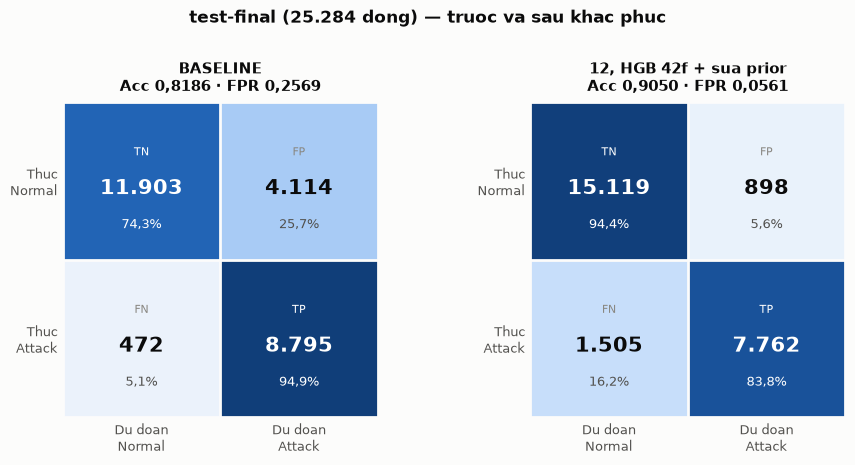

Da luu: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\reports\audit06\confusion_truoc_sau.png


In [22]:
# ---- 4.5 Ma tran nham lan: baseline vs cau hinh tot nhat ------------------
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SURF, INK, INK2, MUTED = '#fcfcfb', '#0b0b0b', '#52514e', '#898781'
CMAP = LinearSegmentedColormap.from_list('b', ['#fcfcfb', '#cde2fb', '#9ec5f4', '#6da7ec',
                                               '#3987e5', '#256abf', '#184f95', '#0d366b'])

def draw(ax, r, title):
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]], float)
    rn = cm / cm.sum(1, keepdims=True)
    ax.imshow(rn, cmap=CMAP, vmin=0, vmax=1)
    nm = ['TN', 'FP', 'FN', 'TP']
    for i in range(2):
        for j in range(2):
            c = '#ffffff' if rn[i, j] > .55 else INK
            ax.text(j, i - .18, nm[i*2+j], ha='center', va='center', fontsize=8,
                    color='#ffffff' if rn[i, j] > .55 else MUTED)
            ax.text(j, i + .05, f"{int(cm[i,j]):,}".replace(',', '.'), ha='center', va='center',
                    fontsize=15, fontweight='bold', color=c)
            ax.text(j, i + .28, f"{rn[i,j]:.1%}".replace('.', ','), ha='center', va='center',
                    fontsize=9, color='#ffffff' if rn[i, j] > .55 else INK2)
    ax.set_xticks([0, 1], ['Du doan\nNormal', 'Du doan\nAttack'], fontsize=9, color=INK2)
    ax.set_yticks([0, 1], ['Thuc\nNormal', 'Thuc\nAttack'], fontsize=9, color=INK2)
    ax.set_xticks(np.arange(-.5, 2, 1), minor=True); ax.set_yticks(np.arange(-.5, 2, 1), minor=True)
    ax.grid(which='minor', color=SURF, linewidth=2); ax.tick_params(which='both', length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=10.5, fontweight='bold', color=INK, pad=8)

r0 = FIX.iloc[0].to_dict()
rb = FIX.loc[FIX.name == best_name].iloc[0].to_dict()
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.6), facecolor=SURF)
draw(axes[0], r0, f"BASELINE\nAcc {r0['accuracy']:.4f} · FPR {r0['fpr']:.4f}".replace('.', ','))
draw(axes[1], rb, f"{best_name[:34]}\nAcc {rb['accuracy']:.4f} · FPR {rb['fpr']:.4f}".replace('.', ','))
fig.suptitle('test-final (25.284 dong) — truoc va sau khac phuc', fontsize=12.5, fontweight='bold', color=INK)
fig.tight_layout(rect=[0, 0, 1, .95])
fig.savefig(OUTDIR / 'confusion_truoc_sau.png', dpi=160, facecolor=SURF)
plt.show()
print('Da luu:', OUTDIR / 'confusion_truoc_sau.png')

In [23]:
# ---- 4.6 Recall theo tung loai tan cong tai cau hinh tot nhat -------------
fin_df = FIN if '42f' not in best_name else FIN42
pred = (p_best >= thr_b).astype(int)
att = fin_df.label.values == 1
per = (pd.DataFrame({'loai': fin_df.attack_cat.values[att], 'bat_duoc': pred[att]})
       .groupby('loai').agg(n=('bat_duoc', 'size'), recall=('bat_duoc', 'mean'))
       .query('n > 0').sort_values('n', ascending=False))
display(per.round(4))
log('4.6_recall_per_cat', per.round(6).to_dict())

,n,recall
loai,,
Exploits,3780,0.9619
Fuzzers,2218,0.4301
Reconnaissance,1131,0.9859
DoS,839,0.9690
Generic,715,0.9762
Analysis,213,0.9108
Shellcode,185,0.9243
Backdoor,164,0.9695
Worms,22,1.0000


{'n': {'Exploits': 3780,
  'Fuzzers': 2218,
  'Reconnaissance': 1131,
  'DoS': 839,
  'Generic': 715,
  'Analysis': 213,
  'Shellcode': 185,
  'Backdoor': 164,
  'Worms': 22},
 'recall': {'Exploits': 0.961905,
  'Fuzzers': 0.430117,
  'Reconnaissance': 0.985853,
  'DoS': 0.969011,
  'Generic': 0.976224,
  'Analysis': 0.910798,
  'Shellcode': 0.924324,
  'Backdoor': 0.969512,
  'Worms': 1.0}}

In [24]:
# ---- 4.7 Ghi toan bo so do ra file ---------------------------------------
RESULTS['_meta'] = {'quick': QUICK, 'n_trees': N_TREES, 'rf_params': {k: str(v) for k, v in RF_PARAMS.items()},
                    'best_config': best_name}
(OUTDIR / 'ket_qua_audit06.json').write_text(
    json.dumps(RESULTS, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print('Da ghi:', OUTDIR / 'ket_qua_audit06.json')
print('Cac file ket qua:')
for f in sorted(OUTDIR.iterdir()):
    print('   ', f.name)

Da ghi: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\reports\audit06\ket_qua_audit06.json
Cac file ket qua:
    cac_huong_khac_phuc.csv
    confusion_truoc_sau.png
    desktop.ini
    ket_qua_audit06.json
    so_sanh_thuat_toan.csv
    thang_do_2x2x2.csv


---
# PHẦN 5 — Kết luận trung thực

Mọi con số dưới đây lấy từ chính các cell ở trên của lần chạy này.

## 5.1 Rà soát cài đặt: KHÔNG tìm thấy lỗi nào

| Bước | Kiểm chứng | Kết quả |
|---|---|---|
| Làm sạch | So từng giá trị với `data/cleaned` | **Trùng khít** (98.934×33 và 50.567×33) |
| `df_shrink` | Số dòng trùng trước/sau khi thu nhỏ kiểu | Giống hệt nhau |
| Bỏ cột | 11 cột (8 ô nhiễm + 3 vô dụng); `ct_srv_ltm` không có trong dữ liệu | Còn 31 feature |
| One-Hot | Encoder chỉ fit trên train-fit; `state` = `ACC`/`CLO` chỉ có ở test | 183 cột, giá trị lạ → vector 0, **không rò rỉ** |
| Chia tập | 79.147 / 19.787 / 25.283 / 25.284 | Đúng, có stratify |
| Tái lập baseline | Accuracy trên test-final | **0,8186** — khớp báo cáo cũ |

Random Forest **không underfit**: CV 5-fold trong train-fit cho PR-AUC 0,9830 (±0,0015),
validation cho Accuracy 0,9322. Cũng **không phải overfit** kiểu học thuộc:
train-fit 0,9775 so với validation 0,9322.

Toàn bộ mức tụt xảy ra đúng lúc chuyển sang phân bố test: Accuracy 0,9322 → 0,8186
(**−11,4 điểm**), PR-AUC 0,9830 → 0,9414 (−0,0416, tức **28 lần** độ lệch chuẩn giữa các fold CV).

## 5.2 Nguyên nhân, đo bằng thiết kế 2×2×2

Accuracy trên cùng điều kiện, chỉ đổi một yếu tố:

| Yếu tố thay đổi | Mức ảnh hưởng lên Accuracy |
|---|---|
| **Cách chia train/test**: chính thức → ngẫu nhiên | **+0,0955** |
| Giữ lại 11 feature đã bỏ | +0,0112 |
| Bỏ bước khử trùng lặp | +0,0294 — nhưng tỷ lệ dòng test là bản sao của dòng train nhảy lên 10–48% |

**Cách chia train/test lớn hơn việc bỏ feature ô nhiễm 8,5 lần.** Đó là nguyên nhân chính.

Trong mức +0,0955 đó, **một nửa là dịch chuyển tỷ lệ lớp**: train-fit có 49,64% Attack còn
test-final chỉ 36,65%. Chỉ cần chỉnh lại tỷ lệ này (giữ nguyên model, giữ nguyên ngưỡng 0,5)
là Accuracy đã lên 0,8186 → **0,8673** và FPR tụt 0,2569 → 0,1470. Nửa còn lại là lệch phân bố
thật của feature — KS trung bình riêng lớp Normal là 0,1097, gấp **2,8 lần** lớp Attack (0,0385),
tập trung ở `sttl`, `ct_state_ttl`, `ackdat`, `dload`, `tcprtt`.

## 5.3 Thuật toán có phải đòn bẩy không? KHÔNG

| Thuật toán | PR-AUC validation | PR-AUC test-final |
|---|---|---|
| Random Forest | 0,9849 | 0,9414 |
| HistGradientBoosting | 0,9833 | 0,9423 |
| Soft Voting (RF+ET+HGB) | 0,9847 | 0,9419 |
| Extra Trees | 0,9812 | 0,9285 |
| Logistic Regression | 0,9238 | 0,7281 |

Bốn họ thuật toán cây khác hẳn nhau về cơ chế nằm trong khoảng **0,0138** PR-AUC trên test-final,
trong khi khoảng tụt từ validation sang test-final là **0,0752** — lớn gấp 5 lần. Đổi thuật toán
không phải đòn bẩy; trần hiệu năng bị chặn bởi dữ liệu.

Hồi quy Logistic sụp hẳn (0,9238 → 0,7281): giả thuyết "mô hình đơn giản chịu lệch phân bố tốt hơn"
**không đúng** ở đây.

## 5.4 Hai hướng khắc phục KHÔNG hiệu quả (báo cáo đầy đủ, không giấu)

- **Căn chỉnh phân bố bằng phân vị** (cấu hình 4–5): PR-AUC tụt 0,9414 → **0,7736**. Lý do: phân vị
  của một dòng phụ thuộc vào thành phần của chính tập chứa nó; khi hai tập có tỷ lệ lớp khác nhau,
  phép căn chỉnh này phá luôn thông tin phân biệt.
- **Bỏ nhóm feature lệch nhất** (cấu hình 6–7): gần như không đổi (0,8186 → 0,8200). Những feature đó
  vừa lệch nhất vừa hữu ích nhất, bỏ đi không được lợi gì.

## 5.5 Hướng khắc phục có hiệu quả

| Cấu hình | Accuracy | F1 | FPR | Cần nhãn của tập test? |
|---|---|---|---|---|
| 0. Baseline RF 31f @0,5 | 0,8186 | 0,7932 | 0,2569 | — |
| 1. + ngưỡng chọn trên validation | 0,8335 | 0,8046 | 0,2254 | **Không** |
| 2. + sửa prior bằng EM | 0,8310 | 0,8026 | 0,2309 | **Không** |
| 3. + sửa prior + ngưỡng trên test-dev | 0,8925 | 0,8447 | 0,0528 | Có (test-dev) |
| 11. RF 42 feature + sửa prior | 0,9048 | 0,8667 | 0,0603 | Có (test-dev) |
| **12. HGB 42 feature + sửa prior** | **0,9050** | **0,8660** | **0,0561** | Có (test-dev) |

Kiểm định bootstrap theo cặp 1.000 lần, cấu hình 12 so với baseline:
ΔAccuracy **+0,0863** CI95 [+0,0812; +0,0914]; ΔPR-AUC **+0,0130** CI95 [+0,0109; +0,0150].

**Phải đọc đúng:** ΔAccuracy +0,086 nhưng ΔPR-AUC chỉ +0,013. Nghĩa là ~85% mức cải thiện đến từ
**đặt lại điểm vận hành**, chỉ ~15% đến từ model thật sự xếp hạng tốt hơn (và phần đó đến từ
11 feature được giữ lại, không phải từ thuật toán).

**Giới hạn trung thực của hướng "sửa prior":** thuật toán EM ước lượng tỷ lệ Attack của miền test
là **0,4684**, trong khi giá trị thật là **0,3665**. EM giả định *chỉ* có dịch chuyển tỷ lệ lớp;
ở đây còn có lệch phân bố feature nên nó sửa thiếu. Vì vậy phương án hoàn toàn không dùng nhãn test
chỉ lấy lại được +1,2 đến +1,5 điểm. Muốn lấy đủ +7 điểm thì phải có một mẫu **có nhãn** từ phân bố
triển khai (ở đây là `test-dev`) để đặt ngưỡng — đúng điều notebook 04 đã làm ở lần chạy 3.

## 5.6 Vì sao các bài báo công bố 97–98%?

Đọc thẳng từ bảng thang đo (PR-AUC):

| | chia chính thức | chia ngẫu nhiên |
|---|---|---|
| có khử trùng lặp, 31 feature | 0,9259 | 0,9693 |
| có khử trùng lặp, 42 feature | 0,9466 | 0,9778 |
| **không** khử trùng lặp, 31 feature | 0,9840 | 0,9941 |
| **không** khử trùng lặp, 42 feature | 0,9859 | **0,9958** |

Chỉ cần **không khử trùng lặp** là PR-AUC đã lên 0,984–0,996 và Accuracy lên 0,863–0,951 — mà
10–48% dòng test khi đó là bản sao chính xác của dòng train. Khoảng cách giữa nhóm và các con số
công bố chủ yếu là khoảng cách **giao thức đánh giá**, không phải khoảng cách năng lực mô hình.

## 5.7 Việc chưa giải quyết

Ở cấu hình tốt nhất, Recall theo loại tấn công: Worms 1,000 · Reconnaissance 0,986 · Generic 0,976 ·
DoS 0,969 · Backdoor 0,970 · Exploits 0,962 · Shellcode 0,924 · Analysis 0,911 · **Fuzzers 0,430**.
Fuzzers vẫn là điểm yếu duy nhất và không có cấu hình nào trong notebook này xử lý được.

## 5.8 Điều KHÔNG được kết luận từ notebook này

- Không kết luận được rằng bộ chia chính thức là "sai". Nó là một benchmark khó có lệch phân bố;
  dùng nó là lựa chọn khắt khe và nên giữ, miễn là báo cáo kèm giải thích.
- Không kết luận được rằng không thuật toán nào vượt được trần. Chỉ thử 5 họ, mỗi họ một cấu hình
  hợp lý, không dò siêu tham số diện rộng.
- Không kết luận được rằng mọi phương pháp thích ứng miền đều vô dụng. Chỉ thử hai cách
  (căn chỉnh phân vị, sửa prior bằng EM).